# Interpretability 10B: swap

The multitask parity problem has 10 input bits $(x_1, x_2, \cdots, x_{10})$, $x_i\in\{0,1\}$.

The are five output bits $y_1, \cdots, y_5$, where $y_i = x_{2i-1} + x_{2i-1} ({\rm mod} 2)$

In [1]:
import torch
from xkan import KANNetwork, create_dataset, fit
from xkan.interp import auto_swap
from xkan.viz import plot

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

model = KANNetwork([10,10,5], seed=1, device=device)
x = torch.normal(0,1,size=(100,2), device=device)

#f = lambda x: torch.exp(torch.sin(torch.pi*x[:,[0]])+x[:,[1]]**2)
f = lambda x: torch.cat([x[:,[0]] + x[:,[1]], x[:,[2]] + x[:,[3]], x[:,[4]] + x[:,[5]], x[:,[6]] + x[:,[7]], x[:,[8]] + x[:,[9]]], dim=1)
train, test = create_dataset(f, n_var=10, device=device)
history = fit(model, train, test, steps=20, lamb=1e-2)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)

cuda


train RMSE 0.08177388781817797 test RMSE 0.07615219375466434


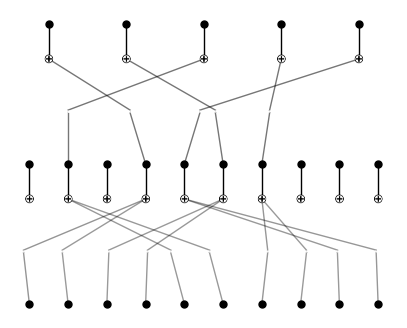

In [2]:
plot(model, train['x']);

In [3]:
model = auto_swap(model, train['x'])

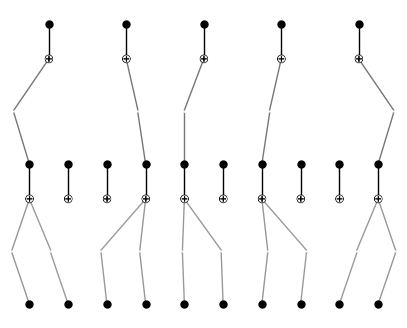

In [4]:
plot(model, train['x']);

In [5]:
# MLP
import numpy as np
import torch
from xkan import create_dataset_from_data
from xkan.contrib.mlp import MLP

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

inputs = []
for i in range(2**10):
    string = "{0:b}".format(i)
    sample = [int(string[i]) for i in range(len(string))]
    sample = (10 - len(sample)) * [0] + sample
    inputs.append(sample)
   
inputs = np.array(inputs).astype(np.float32)
labels = np.sum(inputs.reshape(2**10,5,2), axis=2) % 2
inputs = torch.tensor(inputs)
labels = torch.tensor(labels)

train, test = create_dataset_from_data(inputs, labels, device=device)

model = MLP(width=[10,20,5], seed=5, device=device)
results = model.fit(train, test, steps=100, lamb=2e-4, reg_metric='w')
print('train RMSE', float(results['train_loss'][-1]), 'test RMSE', float(results['test_loss'][-1]))

cuda


train RMSE 0.004330691881477833 test RMSE 0.004385207314044237


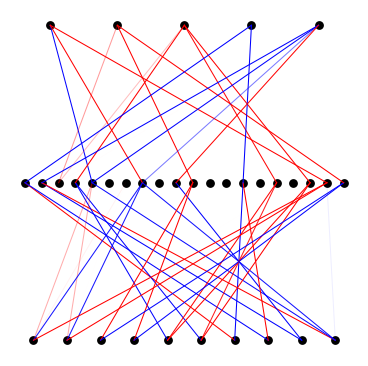

In [6]:
# the MLP baseline (xkan.contrib.mlp.MLP) keeps its own plot and auto_swap methods
model.plot(scale=1.5)

In [7]:
model.auto_swap()

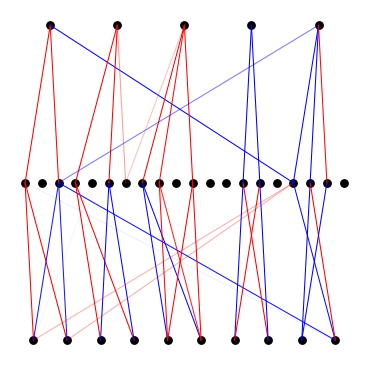

In [8]:
model.plot(scale=1.5)

In [9]:
model.auto_swap()

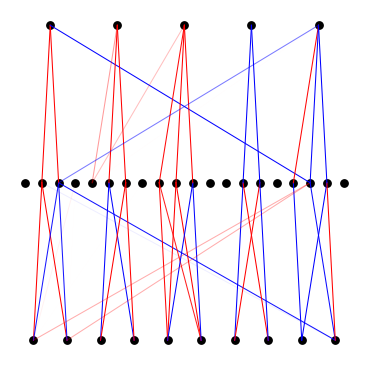

In [10]:
model.plot(scale=1.5)